# Módulo 2 - Punto 2.2: Morfología matemática

Toda la lógica del cálculo está en `src/modulo2/morfologia.py`; este notebook se encarga de llamar a los módulos y visualizar los resultados.

## 0. Configuración del entorno e importaciones
Se configura la ruta raíz del repositorio y se importan las librerías necesarias.

In [4]:
# --- Imports de la librería estándar ---
import sys                 
from pathlib import Path   

# --- Configurar la raíz del repositorio ---
# Path.cwd() = carpeta desde donde corre el notebook (normalmente notebooks/).
# Subimos carpetas hasta encontrar config.yaml: esa es la raíz.
# Así funciona tanto si VS Code abre el notebook desde notebooks/ como desde la raíz.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:          # llegamos a "/" sin encontrarlo
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent

# Insertamos la raíz al principio de sys.path (posición 0 = máxima prioridad).
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros y propios
import numpy as np  
import pandas as pd 
import itertools
import matplotlib.pyplot as plt    
import matplotlib.patches as patches  
import skimage as ski
import cv2
from IPython.display import display
from scipy import ndimage as ndi


from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm   
from src.modulo1 import calidad_filtrado as cf
from src.modulo2 import segmentacion as seg
from src.modulo2 import morfologia as morf
from src.modulo2 import anotacion as an
from src.modulo2 import metricas as me




## 1. Carga de Datos y Configuración Global
Se leen los parámetros desde `config.yaml`, se definen las rutas de salida e inicializan las imágenes de trabajo.

In [5]:
# Cargar configuración global
cfg = cargar_config(raiz / "config.yaml")

# Directorio de salida de resultados
carpeta_res = raiz / "results" / "modulo2"
carpeta_res.mkdir(parents=True, exist_ok=True)

# Carga de imagen y extracción de la ROI
img = cm.obtener_frame(cfg, raiz)
roi = cm.recortar_roi(img, cfg["roi"]) 
roi_grises = cf.conv_grises(roi) 

#=======================================================================
# EXTRACCIÓN DE PARÁMETROS DESDE config.yaml
#=======================================================================

# Parámetros para Watershed
w = cfg["modulo2"]["watershed"]
factor_interior= w["factor_interior"]
factor_anillo_interior= w["factor_anillo_interior"]
factor_anillo_exterior= w["factor_anillo_exterior"]

# Parámetros para morfología
m = cfg["modulo2"]["morfologia"]
kernel = m["kernel"]
iteraciones = m["iteraciones"]
kernel_forma = m["kernel_forma"]

print(f"Resultados en: {carpeta_res}")

Resultados en: c:\Users\Camila\Desktop\Guia_Imagenes\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo2


## 2. Máscara binaria de Watershed

La máscara de la pupila se calcula acá con `segmentar_pupila` (`src/modulo2/segmentacion.py`), que encadena grises, CLAHE, estimación de la pupila, marcadores y Watershed sobre el gradiente Sobel, con los parámetros de `config.yaml`. Devuelve la máscara en `uint8` (255 = pupila, 0 = fondo), el formato que requieren las funciones de OpenCV, y la estimación inicial de centro y radio. Es la máscara sobre la que se aplica la morfología.

In [6]:
# Máscara de la pupila con Watershed (uint8: 255 = pupila, 0 = fondo)
res_ws = seg.segmentar_pupila(roi, cfg)
if res_ws["pupila"] is None:
    raise RuntimeError("No se encontró la pupila en el frame de trabajo.")
mascara_watershed = res_ws["mascara"]


## 3. Aplicación de operaciones morfológicas, combinaciones y esqueletización
La morfología matemática es un mejoramiento de la segmentación. Sus operaciones duales trabajan sobre la máscara binaria para eliminar imperfecciones y mejorar la forma. Opera de forma similar a un filtro espacial: un elemento estructurante (kernel) recorre una imagen píxel a píxel, reescribiendo el valor del píxel según una regla lógica.  Las funciones están en `src/modulo2/morfologia.py`:

* **Erosión:** el píxel de salida vale 1 solo si el kernel *encaja completamente* (fit) en la región blanca. Reduce los objetos, expande el fondo y elimina puntos blancos aislados.
* **Dilatación:** el píxel de salida vale 1 si el kernel *toca al menos un píxel blanco* (hit). Expande los objetos y conecta pequeñas discontinuidades.
* **Apertura:** erosión seguida de dilatación, (A⊖B)⊕B. Elimina filamentos finos, salientes y ruido blanco externo sin cambiar el tamaño global de la masa principal.
* **Cierre:** dilatación seguida de erosión, (A⊕B)⊖B. Rellena grietas y huecos internos sin agrandar la superficie exterior.
* **Apertura + cierre y cierre + apertura:** combinaciones de las dos anteriores; el orden importa porque las operaciones no son conmutativas.
* **Esqueleto del contorno:** se extrae el borde con el gradiente morfológico (dilatación menos erosión) y se adelgaza con `skeletonize` de scikit-image hasta una curva de 1 píxel de espesor, conectada y centrada. Es el mismo objetivo que el adelgazamiento por Hit-or-Miss visto en clase, pero con otro algoritmo. El resultado es el contorno de la pupila, no el esqueleto de su interior.

Erosión y dilatación no son inversas sino duales: erosionar una imagen dilatada no recupera la forma original. En los bordes de la imagen el kernel necesita valores fuera de ella (padding); OpenCV lo resuelve internamente con un relleno neutro, de modo que el borde no erosiona ni agrega píxeles. En este trabajo no tiene efecto, porque la pupila está en el centro de la ROI y la máscara no toca los bordes. El elemento estructurante elíptico se eligió por la forma de la pupila; con `k=3` la elipse de OpenCV equivale a una cruz.

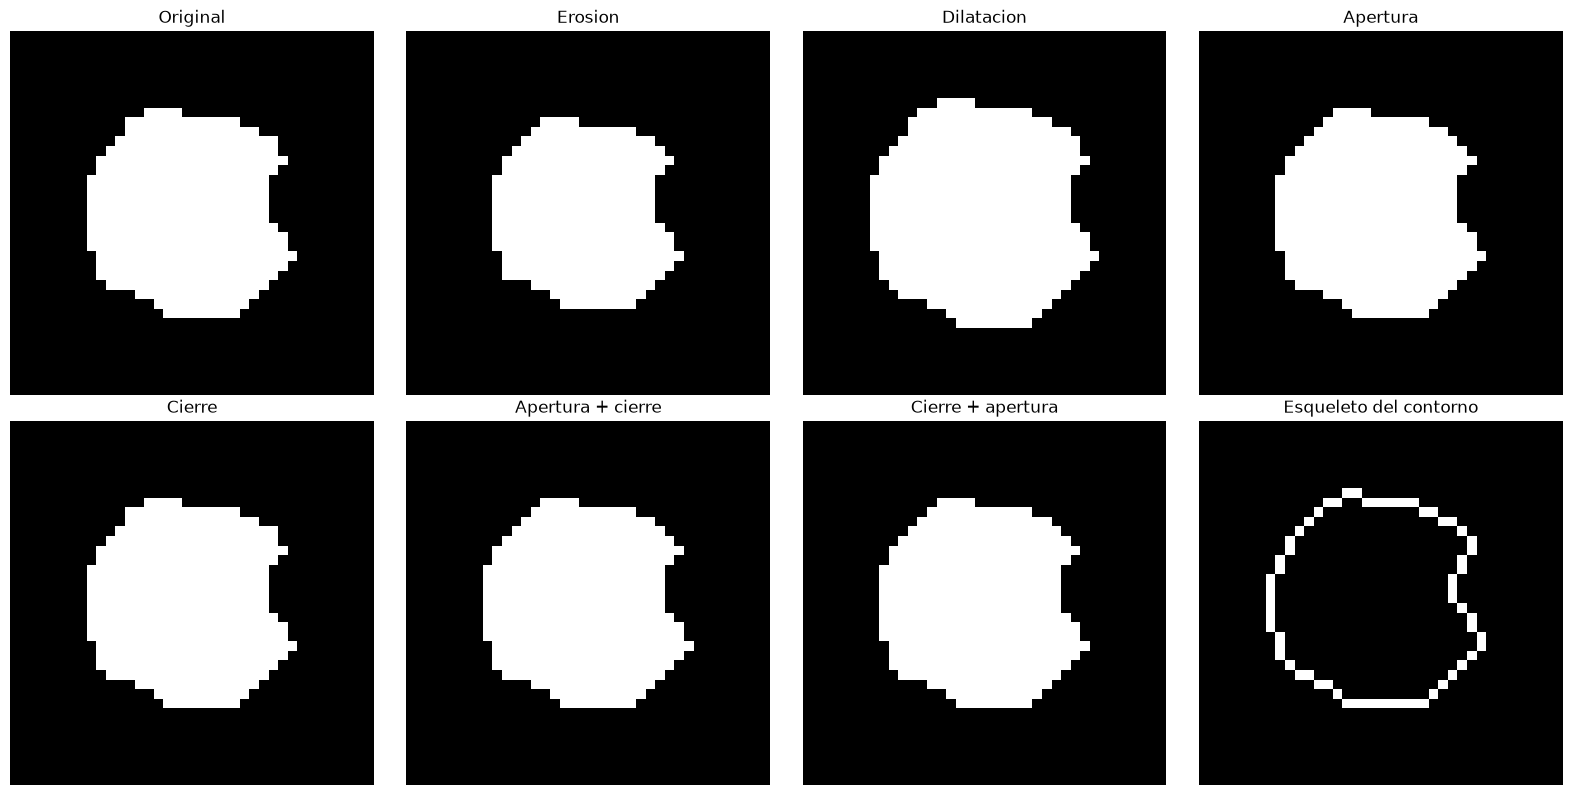

In [7]:
# 3. Aplicación y visualización de operaciones morfológicas

resultados = morf.comparar_morfologia(
    mascara_watershed,
    k=kernel,
    iteraciones=iteraciones,
    kernel_forma=kernel_forma
)

# Recortar alrededor de la pupila para visualizar mejor los cambios
ys, xs = np.nonzero(mascara_watershed)
margen = 8

y0 = max(ys.min() - margen, 0)
y1 = min(ys.max() + margen + 1, mascara_watershed.shape[0])
x0 = max(xs.min() - margen, 0)
x1 = min(xs.max() + margen + 1, mascara_watershed.shape[1])

# Mostrar los resultados con zoom
fig, ejes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (nombre, imagen) in zip(ejes.flat, resultados.items()):
    ax.imshow(
        imagen[y0:y1, x0:x1],
        cmap="gray",
        vmin=0,
        vmax=255
    )
    ax.set_title(nombre)
    ax.axis("off")

plt.tight_layout()

# Guardar la figura
fig.savefig(
    carpeta_res / "2_2_3_operaciones_morfologicas.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

La figura muestra la máscara original de la pupila y los resultados obtenidos tras aplicar distintas operaciones morfológicas con un kernel de 3x3 (k=3) y una iteración, en una región recortada alrededor de la pupila.

Obsérvese que la máscara original presenta irregularidades en el borde superior izquierdo y una hendidura pequeña en el borde lateral derecho. La erosión reduce el área de la pupila, mientras que la dilatación la aumenta, disimulando las irregularidades de la parte superior izquierda y completando parcialmente la muesca del lado derecho.

La apertura, el cierre y sus combinaciones producen cambios poco perceptibles respecto de la máscara original, sin reducir las irregularidades.

Finalmente, el esqueleto representa el contorno de la pupila mediante una curva cerrada de aproximadamente un píxel de grosor, logrando una forma circular consistente, aunque con la muesca en el borde derecho antes mencionada.

## 4. Anotación manual del contorno pupilar
Para evaluar objetivamente la segmentación se necesita una referencia: el contorno real de la pupila marcado a mano. Primero se miran varios frames candidatos del video. Aparecen los ROIs en una ventana aparte, se marca la pupila a mano y se presiona Enter para continuar

True


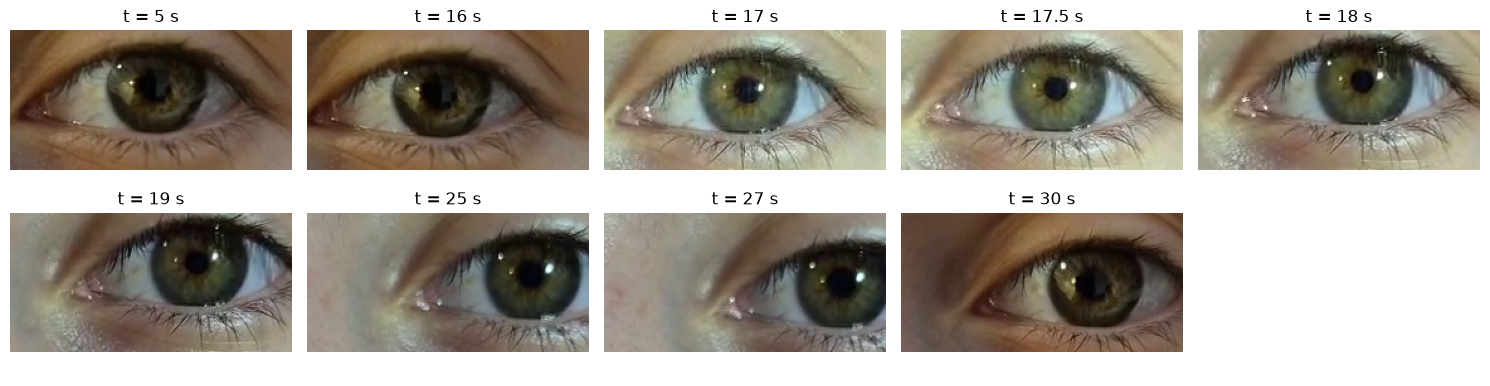

In [8]:
# Frames candidatos del video, para elegir cuáles anotar.
ruta_video = raiz / cfg["entrada"]["video_path"]
print(ruta_video.exists())      # tiene que dar True; si da False, el video no está en el repositorio.

tiempos = [5, 16, 17, 17.5, 18, 19, 25, 27, 30]

cols = 5
filas = int(np.ceil(len(tiempos) / cols))
plt.close('all')
fig, ejes = plt.subplots(filas, cols, figsize=(3 * cols, 2 * filas))
for eje, t in zip(ejes.ravel(), tiempos):
    frame = cm.extraer_frame(ruta_video, t)
    eje.imshow(cm.recortar_roi(frame, cfg["roi"]))
    eje.set_title(f"t = {t} s")
    eje.axis("off")
for eje in ejes.ravel()[len(tiempos):]:     # apaga los ejes sobrantes
    eje.axis("off")
plt.tight_layout()
plt.show()

Se eligieron 6 de los 9 candidatos: **5; 16; 17; 17,5; 18 y 19**. Ninguno tiene parpadeo; la elección cubre distintas condiciones de iluminación (los frames de 5 y 16 s son más oscuros) y distintos tamaños de pupila.

En cada frame se hace clic sobre el borde de la pupila (entre 12 y 17 puntos por frame); el polígono resultante se rellena y se guarda como máscara de referencia en `results/modulo2/anotaciones_manuales/`. Las anotaciones quedan guardadas en disco y la celda saltea las que ya existen, por lo que no hace falta anotar de nuevo. La anotación la realizó una sola persona, por lo que no se conoce la variabilidad entre observadores.

In [9]:
carpeta_anot = carpeta_res / "anotaciones_manuales"
tiempos_anotar = [5, 16, 17, 17.5, 18, 19]   # ← Tiempos representativos elegidos

an.anotar_frames(
    obtener_roi=lambda t: cv2.cvtColor(cm.recortar_roi(cm.extraer_frame(ruta_video, t), cfg["roi"]), cv2.COLOR_RGB2BGR),
    tiempos=tiempos_anotar,
    carpeta=carpeta_anot,
    modo="poligono",
)

t = 5 s: ya anotado, se saltea.
t = 16 s: ya anotado, se saltea.
t = 17 s: ya anotado, se saltea.
t = 17.5 s: ya anotado, se saltea.
t = 18 s: ya anotado, se saltea.
t = 19 s: ya anotado, se saltea.


## 5. Métricas de evaluación
Cada máscara se compara con la referencia manual mediante las siguientes métricas: 
- **Dice** = 2|A∩B| / (|A|+|B|). Mide cuánto se superponen la máscara anotada manualmente y cada máscara automática, normalizando por el tamaño de ambas.
- **Jaccard (IoU)** = |A∩B| / |A∪B|. Compara los píxeles compartidos por ambas máscaras con todos los píxeles que aparecen en al menos una de las dos máscaras.

En Dice y Jaccard, cuanto más cerca de 1, mayor es la coincidencia. Un valor 1 significa que las máscaras son idénticas. Miden prácticamente lo mismo, pero Dice suele dar un valor numérico mayor que IoU para una misma comparación.

-  **Precisión** = Verdaderos Positivos / (Verdaderos Positivos + Falsos Positivos). De todos los píxeles que en la máscara automática se marcaron como pupila, ¿qué proporción realmente pertenece a la pupila según la referencia utilizada?. Si la precisión es alta, el algoritmo agrega pocos píxeles demás erroneamente. En cambio, si es baja, incluye muchos píxeles que no deberían estar dentro de la pupila.
-  **Recall**  = Verdaderos Positivos / (Verdaderos Positivos + Falsos Negativos). De todos los píxeles que se marcaron manualmente como parte de la pupila, ¿qué proporción logró detectar el algoritmo? Un recall alto deja afuera pocos píxeles de la pupila real, mientras que un recall bajo pierde una parte importante de la pupila.
  
Estas dos últimas son complementarias: la precisión penaliza lo que sobra, mientras que el recall penaliza lo que falta.

Las métricas distancia media y distancia de Hausdorff se aplican para realizar una comparación del esqueleto generado con el borde de las anotaciones manuales.
- **Distancia media**: mide qué tan lejanos se encuentran los puntos de un contorno de los puntos del otro, en píxeles. Si es baja, el contorno automático sigue de cerca al manual, mientras que si es alta, hay diferencias grandes entre ambos contornos.
- **Distancia de Hausdorff**: mide el peor desvío entre los dos contornos, en píxeles.


**Alineación con la ROI actual.** Las máscaras manuales se guardaron en coordenadas de la ROI que había en `config.yaml` cuando se anotó. Si después se cambia la ROI, la máscara manual y la automática ya no tienen el mismo tamaño ni el mismo origen, y no se pueden comparar píxel a píxel. Para no tener que re-anotar cada vez, `an.alinear_anotaciones` busca dónde estaba la ROI anotada dentro del frame completo (correlación cruzada normalizada con `cv2.matchTemplate` entre el frame y la imagen `contorno_manual_*.png` guardada al anotar) y traslada cada máscara manual a la ROI actual. La tabla de abajo muestra el desplazamiento encontrado y la correlación (cerca de 1 = ubicación confiable); si el área que queda dentro de la ROI actual es menor que la anotada, parte de la pupila anotada quedó fuera de la ROI.

In [10]:
# Anotaciones trasladadas a la ROI actual (ordenadas por tiempo)
anotaciones, alineacion = an.alinear_anotaciones(carpeta_anot, ruta_video, cfg["roi"])
print(alineacion.to_string(index=False))

tablas, masks_ws, pupilas = [], {}, {}
for t, ref in anotaciones.items():
    roi_t = cm.recortar_roi(cm.extraer_frame(ruta_video, t), cfg["roi"])
    res_t = seg.segmentar_pupila(roi_t, cfg)
    if res_t["pupila"] is None:
        print(f"t = {t} s: no se detectó pupila, se omite.")
        continue
    mask_t = res_t["mascara"]
    masks_ws[t] = mask_t
    pupilas[t] = res_t["pupila"]
    res = morf.comparar_morfologia(mask_t, k=kernel, iteraciones=iteraciones,
                                   kernel_forma=kernel_forma)
    df = me.evaluar_metodos(ref, res)
    df["t"] = t
    tablas.append(df)

todo = pd.concat(tablas)
print(todo.groupby("metodo")[["dice", "jaccard", "precision", "recall"]]
          .mean().dropna().round(3).sort_values("dice", ascending=False))
print(todo[todo.metodo.str.contains("Esqueleto")]
          .groupby("metodo")[["dist_media_px", "hausdorff_px"]].mean().round(2))

 t_s  dx_px  dy_px  correlacion forma_anotada forma_roi_actual  area_anotada_px  area_dentro_roi_px
 5.0      0      0     0.923634    (111, 224)       (111, 224)              716                 716
16.0      0      0     0.925987    (111, 224)       (111, 224)              743                 743
17.0      0      0     0.973569    (111, 224)       (111, 224)              389                 389
17.5      0      0     0.976836    (111, 224)       (111, 224)              326                 326
18.0      0      0     0.973511    (111, 224)       (111, 224)              288                 288
19.0      0      0     0.966498    (111, 224)       (111, 224)              296                 296
                    dice  jaccard  precision  recall
metodo                                              
Apertura           0.874    0.779      0.892   0.863
Apertura + cierre  0.873    0.779      0.891   0.863
Cierre + apertura  0.873    0.779      0.890   0.865
Cierre             0.872    0.776  

## 6. Comparación de operaciones morfológicas
Resultados promedio sobre los 6 frames anotados, con los parámetros de `config.yaml` (`k=3`, 1 iteración, elemento elíptico):

| Operación | Dice | Jaccard | Precisión | Recall |
|---|---|---|---|---|
| Erosión | 0,839 | 0,728 | 0,944 | 0,761 |
| Apertura + cierre | 0,873 | 0,779 | 0,891 | 0,863 |
| Apertura | 0,874 | 0,779 | 0,892 | 0,863 |
| Cierre + apertura | 0,873 | 0,779 | 0,890 | 0,865 |
| Original (sin morfología) | 0,871| 0,775 | 0,886 | 0,864 |
| Cierre | 0,872 | 0,776 | 0,884 | 0,866 |
| Dilatación | 0,865 | 0,764 | 0,811 | 0,936 |

El esqueleto del contorno queda a una distancia media de 1,28 px del borde de la referencia, lo cual sugiere que el esqueleto del contorno automático sigue bastante de cerca al borde anotado. En cuanto a la distancia de Hausdorff, se obtuvo 4,8 px, lo cuál podría atribuirse a la zona de la hendidura del lateral derecho de la pupila segmentada. En general, hay una buena correspondencia general del entorno, aunque persisten diferencias puntuales.

Las seis anotaciones cubren la pupila dilatada (≈720–740 px a los 5 y 16 s) y contraída (≈290–390 px a partir de los 17 s). Sobre ellas, la máscara de Watershed sin morfología ya tiene buena concordancia con el contorno manual (Dice = 0,871; Jaccard = 0,775). Además está equilibrada: la precisión (0,886) y el recall (0,864) son parecidos y buenos valores, por lo que no sobresegmenta ni subsegmenta de forma sistemática. Esta es la razón por la cual la apertura, el cierre y sus combinaciones apenas cambian el resultado. La dilatación y la erosión, en cambio, desplazan el borde de toda la máscara y muestran el compromiso entre precisión y recall. La dilatación sube el recall a 0,936 pero baja la precisión a 0,811, porque incorpora iris alrededor de la pupila. La erosión hace lo contrario: precisión de 0,944 pero recall de 0,761, porque recorta parte de la pupila real. Por eso tiene el peor Dice (0,839).

La apertura obtiene el Dice más alto (0,874), aunque la diferencia con las demás es mínima.

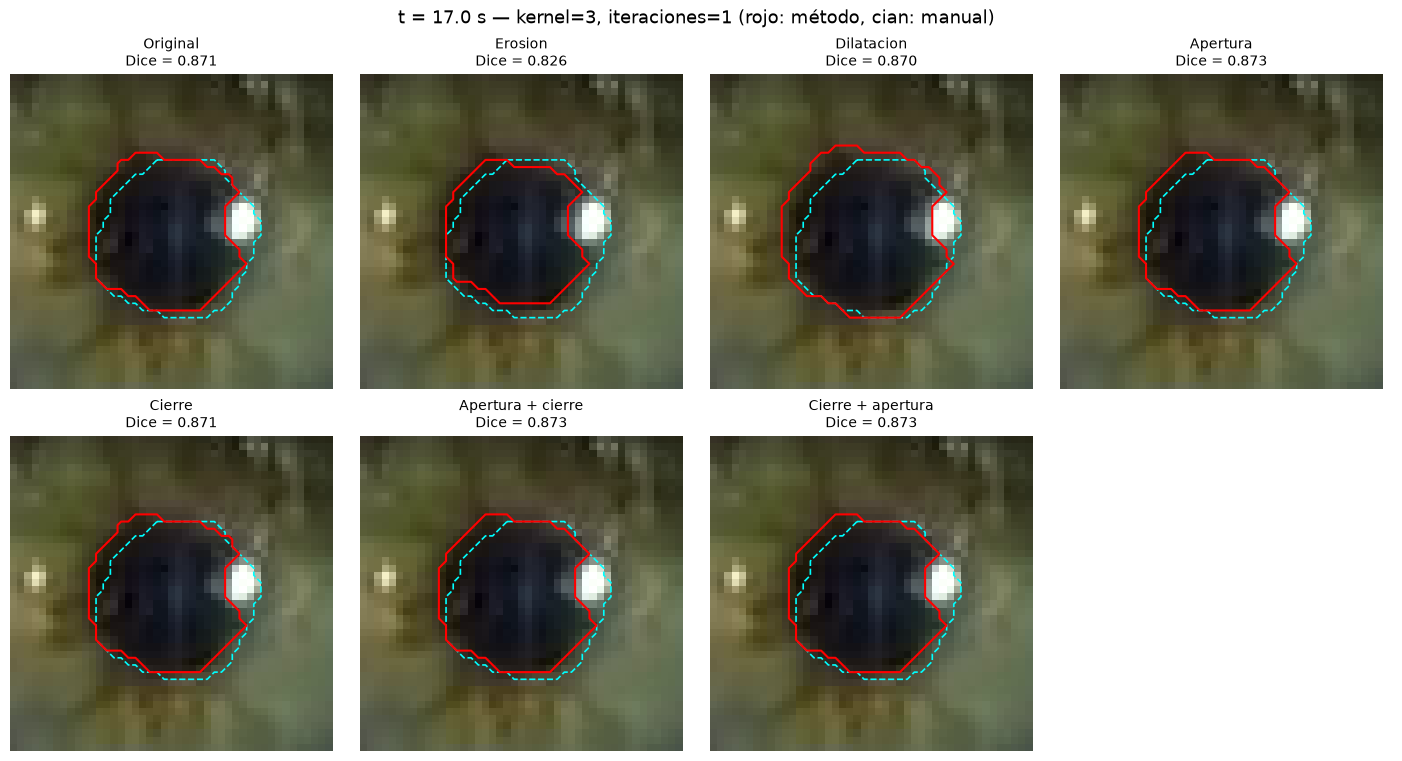

In [14]:
def figura_morfologia(t, k, it, guardar=None):
    ws, manual = masks_ws[t], anotaciones[t]
    roi_t = cm.recortar_roi(cm.extraer_frame(ruta_video, t), cfg["roi"])
    roi_rgb = roi_t if roi_t.ndim == 3 else cv2.cvtColor(roi_t, cv2.COLOR_GRAY2RGB)

    res = morf.comparar_morfologia(ws, k=k, iteraciones=it, kernel_forma=kernel_forma)
    paneles = {n: m_ for n, m_ in res.items() if n != "Esqueleto del contorno"}

    union = manual > 0
    for m_ in paneles.values():
        union = union | (m_ > 0)
    ys, xs = np.nonzero(union)
    mg = 10
    y0, y1 = max(ys.min() - mg, 0), min(ys.max() + mg + 1, roi_rgb.shape[0])
    x0, x1 = max(xs.min() - mg, 0), min(xs.max() + mg + 1, roi_rgb.shape[1])

    fig, ejes = plt.subplots(2, 4, figsize=(14, 7.5), constrained_layout=True)
    fig.suptitle(f"t = {t} s — kernel={k}, iteraciones={it} (rojo: método, cian: manual)",
                 fontsize=13)
    for ax, (nombre, m_) in zip(ejes.flat, paneles.items()):
        ax.imshow(roi_rgb[y0:y1, x0:x1], interpolation="nearest")
        ax.contour((manual[y0:y1, x0:x1] > 0).astype(float), levels=[0.5],
                   colors="cyan", linewidths=1.2, linestyles="--")
        ax.contour((m_[y0:y1, x0:x1] > 0).astype(float), levels=[0.5],
                   colors="red", linewidths=1.5)
        a, b = manual > 0, m_ > 0
        dice = 2 * (a & b).sum() / (a.sum() + b.sum())
        ax.set_title(f"{nombre}\nDice = {dice:.3f}", fontsize=10)
        ax.axis("off")
    for ax in ejes.flat[len(paneles):]:
        ax.axis("off")
    if guardar:
        fig.savefig(carpeta_res / guardar, dpi=150, bbox_inches="tight")
    plt.show()


figura_morfologia(17.0, k=3, it=1, guardar="2_2_6_operaciones_sobre_imagen.png")

## 7. Barrido de parámetros


Se evaluaron distintas operaciones morfológicas utilizando kernels de tamaño k=3,5,7,9 y entre 1 y 3 iteraciones, y calculando distintas métricas:

- `r_rel`: radio efectivo del kernel dividido por el radio de la pupila. Mide qué fracción del radio puede desplazar la operación al borde. Valores bajos indican operaciones suaves; cerca de 1, operaciones que destruyen la máscara.
- `dice`: Dice medio de la máscara procesada contra la anotación manual, promediado sobre los 6 frames.
- `d_dice`: la mejora, es decir, el Dice de la configuración menos el Dice de la máscara original, frame por frame, y luego promediado. Positivo significa que la operación mejora.
- `d_dice_std`: el desvío entre frames de esa diferencia. Si es del mismo orden que d_dice, la mejora no es consistente de un frame a otro.
- `frames_mejora`: en cuántos de los 6 frames el Dice con la operación es mayor que sin ella.
- `ratio_area`: área de la máscara procesada dividida por la de la anotación manual, promediada sobre los frames. Vale 1 si el tamaño coincide, menos de 1 si la máscara es más chica que la manual y más de 1 si es más grande. Sin morfología es 0,980.

In [19]:
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)


def metricas_region(ref, pred):
    """Dice, precisión y recall con las funciones de metricas.py, más la relación de áreas."""
    p, r = me.precision_recall(ref, pred)
    return dict(
        dice=me.dice(ref, pred),
        precision=p,
        recall=r,
        ratio_area=np.count_nonzero(pred) / np.count_nonzero(ref),
    )


filas = []
for t, mask_t in masks_ws.items():
    ref = anotaciones[t]
    r_pup = np.sqrt(np.count_nonzero(mask_t) / np.pi)      # radio estimado (px)
    base = metricas_region(ref, mask_t)

    for k_, it_ in itertools.product([3, 5, 7, 9], [1, 2, 3]):
        res = morf.comparar_morfologia(mask_t, k=k_, iteraciones=it_,
                                       kernel_forma=kernel_forma)
        res.pop("Esqueleto del contorno")
        res.pop("Original")
        r_ef = it_ * (k_ - 1) / 2                           # radio efectivo (px)

        for nombre, pred in res.items():
            m = metricas_region(ref, pred)
            filas.append(dict(
                t=t, k=k_, it=it_, metodo=nombre,
                r_ef=r_ef, r_rel=r_ef / r_pup,
                d_dice=m["dice"] - base["dice"],
                **m,
            ))

barrido = pd.DataFrame(filas)

resumen = (
    barrido.groupby(["metodo", "k", "it"])
    .agg(r_rel=("r_rel", "mean"),
         dice=("dice", "mean"),
         d_dice=("d_dice", "mean"),
         d_dice_std=("d_dice", "std"),
         frames_mejora=("d_dice", lambda x: int((x > 0).sum())),
         ratio_area=("ratio_area", "mean"))
    .round(3)
    .reset_index()
)


def mostrar(df):
    """Muestra un DataFrame como tabla limpia: redondeado y con índice 0..n-1."""
    display(df.round(3).reset_index(drop=True))


linea_base = np.mean([me.dice(anotaciones[t], m) for t, m in masks_ws.items()])
print(f"Línea base (sin morfología): Dice medio = {linea_base:.3f}\n")

print("Top 10 con radio efectivo <= 1/3 del radio de la pupila:")
top = (resumen[resumen.r_rel <= 0.33]
       .sort_values("d_dice", ascending=False)
       .head(10))
mostrar(top)


Línea base (sin morfología): Dice medio = 0.871

Top 10 con radio efectivo <= 1/3 del radio de la pupila:


,metodo,k,it,r_rel,dice,d_dice,d_dice_std,frames_mejora,ratio_area
0,Apertura + cierre,3,3,0.265,0.877,0.006,0.010,4,0.943
1,Cierre + apertura,3,3,0.265,0.877,0.006,0.007,5,0.966
2,Cierre + apertura,7,1,0.265,0.876,0.005,0.008,4,0.964
3,Apertura,3,3,0.265,0.876,0.005,0.011,4,0.942
4,Apertura + cierre,3,2,0.177,0.875,0.004,0.004,5,0.956
5,Cierre + apertura,3,2,0.177,0.876,0.004,0.005,5,0.968
6,Cierre,3,3,0.265,0.874,0.003,0.007,4,0.991
7,Apertura + cierre,7,1,0.265,0.875,0.003,0.010,4,0.944
8,Apertura,3,2,0.177,0.874,0.003,0.004,4,0.953
9,Cierre,5,1,0.177,0.873,0.002,0.003,4,0.987


La tabla muestra las diez configuraciones con mayor mejora media del Dice respecto de la máscara de Watershed sin procesar (0,871), entre las que tienen un radio efectivo de kernel no mayor a un tercio del radio de la pupila (`r_rel` ≤ 0,33). 

La mejora del Dice es pequeña: va de +0,002 a +0,006, siendo las mayores las de apertura + cierre y cierre + apertura con k=3 e 3 iteraciones (+0,006). En cada configuración el desvío de la diferencia entre frames (0,003 a 0,011) es del mismo orden que la propia mejora, y la operación mejora el Dice en 4 o 5 de los 6 frames, nunca en los seis. Hay que considerar, además, que estas configuraciones son las mejores entre unas cincuenta evaluadas sobre los mismos frames con que se miden, por lo que parte de la diferencia observada puede deberse a la selección.

La relación de áreas separa dos comportamientos. Las configuraciones que incluyen apertura reducen el área respecto de la anotación (0,942 a 0,968, contra 0,980 sin morfología), lo cual es esperable, ya que la apertura nunca agrega píxeles y elimina los salientes. El cierre solo, en cambio, mantiene la relación de áreas cerca de 1 (0,987 a 0,991), porque no reduce la máscara, aunque es también la operación con menor mejora de Dice (+0,002 y +0,003).

## 8. Diagnóstico de Watershed

La máscara de Watershed sin morfología ha mostrado los siguientes valores de métricas:
- Dice: 0,871.
- Jaccard: 0,775.
- Precisión: 0,886.
- Recall: 0,864.

El Dice de 0,87 no es 1, es decir, la máscara automática y la manual no coinciden en algunos píxeles. La pregunta reside en dónde están esos píxeles no coincidentes. Podrían estar repartidos por la máscara (agujeros dentro de la zona de la pupila o manchas en la zona exterior), o estar pegados al borde debido a que el contorno automático corre uno o dos píxeles hacia adentro o hacia afuera respecto del manual.

Luego, pueden evaluarse distintos aspectos para conocer más acerca del desempeño de la máscara por sí sola (sin morfología):
- Relación entre áreas: el área de la máscara de Watershed dividida por la generada manualmente.
- Desvío del borde en píxeles: cuánto se aleja, en promedio, el contorno automático del manual.
- Porcentaje de error en banda de 2 píxeles: de todos los píxeles que no coinciden, qué porcentaje está a menos de 2 píxeles del borde de la anotación manual. Si es alto, el error está pegado al borde.

In [12]:
def diagnostico_ws(ref, ws):
    a, b = ref > 0, ws > 0
    xor = a ^ b

    borde_a = a & ~ndi.binary_erosion(a)
    borde_b = b & ~ndi.binary_erosion(b)
    dist_a = ndi.distance_transform_edt(~borde_a)     # distancia al borde manual
    dist_b = ndi.distance_transform_edt(~borde_b)     # distancia al borde de Watershed

    r_ref = np.sqrt(a.sum() / np.pi)
    d_medio = np.concatenate([dist_a[borde_b], dist_b[borde_a]]).mean()

    return dict(
        area_ref=int(a.sum()),
        area_ws=int(b.sum()),
        ratio_area=b.sum() / a.sum(),
        sesgo_radio_px=np.sqrt(b.sum() / np.pi) - r_ref,
        desvio_borde_px=d_medio,
        dice=2 * (a & b).sum() / (a.sum() + b.sum()),
        pct_error_en_banda_2px=100 * (xor & (dist_a <= 2)).sum() / max(xor.sum(), 1),
    )

filas = [dict(t=t, **diagnostico_ws(anotaciones[t], masks_ws[t])) for t in masks_ws]
diag = pd.DataFrame(filas)
display(diag.round(3))
print(diag.drop(columns="t").mean().round(3))

,t,area_ref,area_ws,ratio_area,sesgo_radio_px,desvio_borde_px,dice,pct_error_en_banda_2px
0,5.0,716,530,0.740,-2.108,2.594,0.778,63.406
1,16.0,743,734,0.988,-0.093,1.101,0.919,98.319
2,17.0,389,369,0.949,-0.290,1.311,0.871,81.633
3,17.5,326,345,1.058,0.293,1.375,0.864,74.725
4,18.0,288,293,1.017,0.083,0.608,0.936,100.000
5,19.0,296,333,1.125,0.589,1.337,0.859,80.899


area_ref                  459.667
area_ws                   434.000
ratio_area                  0.980
sesgo_radio_px             -0.255
desvio_borde_px             1.388
dice                        0.871
pct_error_en_banda_2px     83.164
dtype: float64


Por un lado, la relación de áreas se mantiene siempre cercana a 1, con oscilaciones hacia ambos lados en los distintos frames. El promedio arroja 0,98. El valor más alejado de 1 corresponde a t=5 segundos, que es un frame con mala iluminación. Luego, Watershed no sobresegmenta ni subsegmenta en forma significativa, salvo en el frame t=5.

Por otro lado, el desvío medio de borde es de 1,4 px en promedio (1,1 px si se excluye el frame de 5 s, con poca iluminación), es decir, cada punto del contorno automático se encuentra, en promedio, a poco más de un píxel del contorno manual. Esta medida no distingue si el contorno cae dentro o fuera de la referencia. El sesgo de radio con signo cambia de signo entre frames (de −2,1 a +0,6 px) y la precisión (0,886) y el recall (0,864) son similares, lo que indica que la máscara de Watershed no está sistemáticamente por dentro ni por fuera de la anotación manual. Como la referencia fue marcada por una sola persona, no es posible separar qué parte de este desvío corresponde al algoritmo y qué parte a la variabilidad de la anotación.


## 9. Conclusión

La máscara de Watershed no presenta un sesgo sistemático de tamaño: la relación de áreas respecto de la anotación manual promedia 0,98, la precisión (0,886) y el recall (0,864) están equilibrados, y el desvío medio de borde es de ≈1,4 px (1,1 px sin el frame de 5 s). La excepción es el frame de t=5 s, donde Watershed subsegmenta (relación de áreas 0,74; Dice 0,778).

El barrido de operaciones morfológicas, restringido a kernels cuyo radio efectivo no supera un tercio del radio de la pupila, mejora el Dice medio como máximo 0,006 respecto de la máscara sin procesar (0,871), con mejora en 4 o 5 de los 6 frames. Esta diferencia es pequeña frente a la variación del Dice entre frames y corresponde a la mejor de unas cincuenta combinaciones evaluadas sobre los mismos frames, por lo que no puede considerarse evidencia de una mejora real. Además, las configuraciones con apertura reducen la relación de áreas de 0,980 a 0,94–0,97, lo que sesga la medición del área de la pupila. 

Por lo tanto, el pipeline final utiliza la máscara de Watershed sin operaciones morfológicas. Estos resultados se basan en seis frames anotados por una sola persona, por lo que deben tomarse como evidencia de este conjunto y no como una propiedad general del método.